# Evolução da participação no ENEM

**Área de análise:** Pará (PA)  
**Referência territorial:** município da escola (ESC)  
**Período:** 1998–2025 para a evolução anual
**Fonte:** `painel`, `dsp`

**OBJETIVO :**

O eixo investiga a evolução do número de participantes do ENEM no Pará, sua distribuição entre os municípios, a concentração territorial da participação e a presença dos inscritos na aplicação do exame. Os resultados descrevem a participação registrada nas bases do projeto e não devem ser interpretados automaticamente como medida da população jovem ou da demanda potencial pelo exame.

<div style="background-color: #f5f0dc; padding: 12px; border-radius: 6px;">
    
> **Nota Metodológica**  
> A cobertura municipal é bastante reduzida nos primeiros anos. Em 1998, há registros de apenas cinco municípios; em 1999, 60; em 2000, 78. A cobertura passa a ser mais ampla a partir de 2001 e alcança 140 municípios em 2003. Por isso, comparações de longo prazo que utilizem 1998 como referência inicial precisam ser interpretadas com cautela.
</div>

## Principais achados
<div style="background-color: #DBEAFE; padding: 12px; border-radius: 6px;">

> **Expansão municipal disseminada**  
> 127 dos 140 municípios comparáveis apresentaram aumento no número de participantes entre 2003 e 2025 (**90,7%** dos municípios analisados).

> **Redução da concentração territorial**  
> O HHI municipal caiu de **0,1389 em 2001** para **0,0495 em 2025**, indicando uma distribuição menos concentrada dos registros entre os municípios.

> **Mudança expressiva em 2024**  
> O número de participantes aumentou **104,1%** em relação a 2023. A magnitude da variação merece atenção na interpretação da série histórica.
 </div>

## Configuração e carga


In [1]:
from _setup2 import *

UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)

painel_esc = out["painel"]["data"].copy()
dsp_esc = out["dsp"]["data"].copy()

print("=" * 46)
print(f"UF: {UF_PROCESSAMENTO}  | Período :{painel_esc['ano'].min()}–{painel_esc['ano'].max()}| Referência: {TIPO_REFERENCIA} ")
print("=" * 46)
print(f"painel  : {painel_esc.shape[0]:,} x {painel_esc.shape[1]}".replace(",", "."))
print(f"dsp     : {dsp_esc.shape[0]:,} x {dsp_esc.shape[1]}".replace(",", "."))
print("=" * 46)


UF: PA  | Período :1998–2025| Referência: ESC 
painel  : 3.625 x 82
dsp     : 250.436 x 17


## 1. Evolução do número de participantes

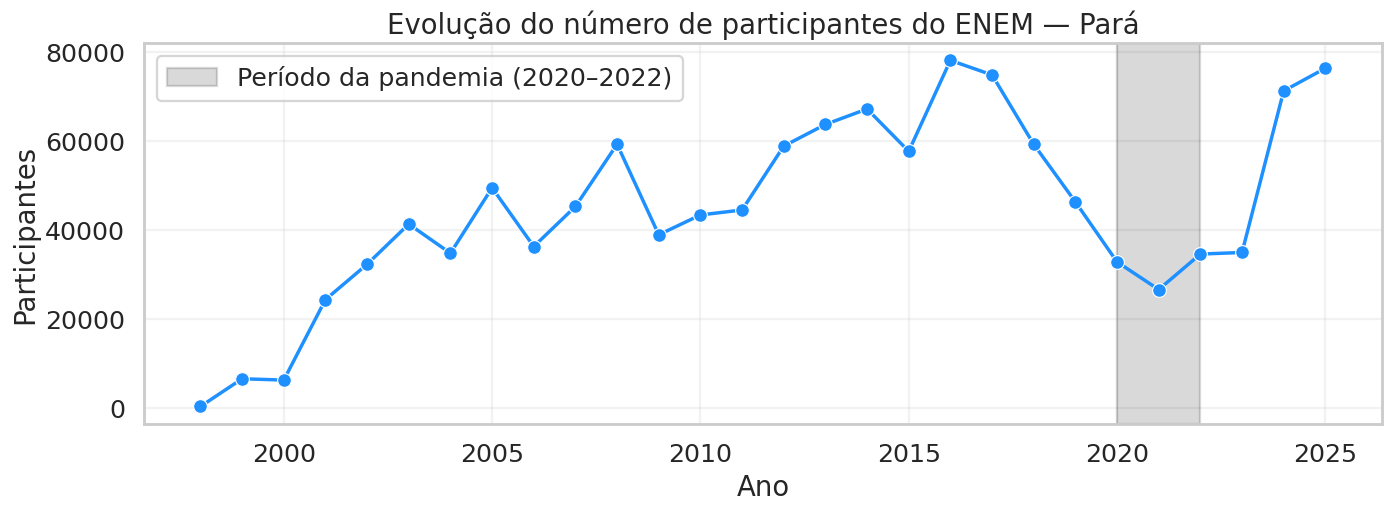

In [2]:
participacao_anual = eda2.calcular_participacao_anual(painel_esc)

fig, ax = plt.subplots(figsize=(13, 5))
eda2.plotar_serie_temporal(
    participacao_anual,
    x="ano",
    y="participantes",
    color='dodgerblue',
    titulo="Evolução do número de participantes do ENEM — Pará",
    xlabel="Ano",
    ylabel="Participantes",
    ax=ax,
)


# Destaque do período da pandemia
ax.axvspan(
    2020, 2022,
    color="black",
    alpha=0.15,
    label="Período da pandemia (2020–2022)"
)
ax.legend()
plt.tight_layout()
plt.show()

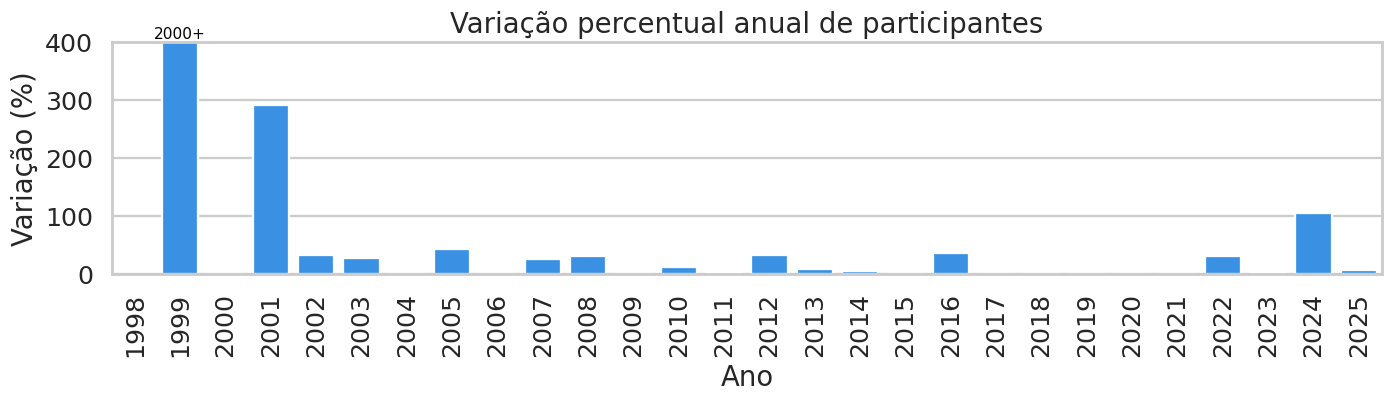

In [3]:
df_plot = participacao_anual[participacao_anual["ano"].between(1998, 2025)]

fig, ax = plt.subplots(figsize=(13, 4))
sns.barplot(data=df_plot,x="ano",y="variacao_percentual",color='dodgerblue',ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.text(x=1,y=400,s="2000+",fontsize=10,color="black",ha="center",  va="bottom")
ax.set(title="Variação percentual anual de participantes",
       xlabel="Ano",
       ylabel="Variação (%)",
       ylim=(0, 400))
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()



### Comentários

O número de participantes registrados cresceu de 288, em 1998, para 76.264, em 2025. Embora o crescimento acumulado seja expressivo, a série apresenta oscilações importantes, com períodos de expansão e retração.

Entre 2001 e 2008, o total passou de 24.295 para 59.189 participantes. Em 2009, houve uma redução para 38.855. Posteriormente, ocorreu uma nova expansão, alcançando 78.031 participantes em 2016, o maior valor até aquele momento.
Entre 2017 e 2021, a participação diminuiu de forma contínua, chegando a 26.554 participantes em 2021. A partir de 2022, a série voltou a crescer. O aumento mais expressivo ocorreu em 2024, quando o total passou de 34.880 para 71.175 participantes, crescimento de aproximadamente 104,1%. Em 2025, houve novo aumento, chegando a 76.264 participantes.

| Ano  | Participantes | Variação em relação ao ano anterior |
| ---- | -------------:| -----------------------------------:|
| 1998 | 288           | —                                   |
| 2001 | 24.295        | +290,7%                             |
| 2008 | 59.189        | +30,9%                              |
| 2009 | 38.855        | -34,4%                              |
| 2012 | 58.769        | +32,3%                              |
| 2016 | 78.031        | +35,5%                              |
| 2019 | 46.241        | -21,9%                              |
| 2020 | 32.759        | -29,2%                              |
| 2021 | 26.554        | -18,9%                              |
| 2022 | 34.524        | +30,0%                              |
| 2023 | 34.880        | +1,0%                               |
| 2024 | 71.175        | +104,1%                             |
| 2025 | 76.264        | +7,1%                               |

A trajetória da participação no ENEM no Pará não foi linear. Há ciclos de expansão e retração, com recuperação expressiva a partir de 2022 e um salto particularmente acentuado em 2024. Esse salto merece atenção antes de ser interpretado como crescimento exclusivamente associado à procura pelo exame: é necessário considerar possíveis mudanças na cobertura, no registro ou na composição dos dados.

O crescimento percentual calculado desde 1998 é influenciado pela cobertura muito pequena daquele ano. Por essa razão, o CAGR de 22,95% informado para 1998–2025 não deve ser apresentado como uma taxa representativa de crescimento estrutural da participação. A comparação entre 2003 e 2025, quando a cobertura municipal já é ampla, é mais adequada para a análise territorial.


## 2. Crescimento e redução por município

A comparação padrão usa o primeiro e o último ano efetivamente disponíveis. A tabela identifica municípios sem observação em um dos extremos; esses casos não devem ser interpretados como crescimento ou retração comparável.

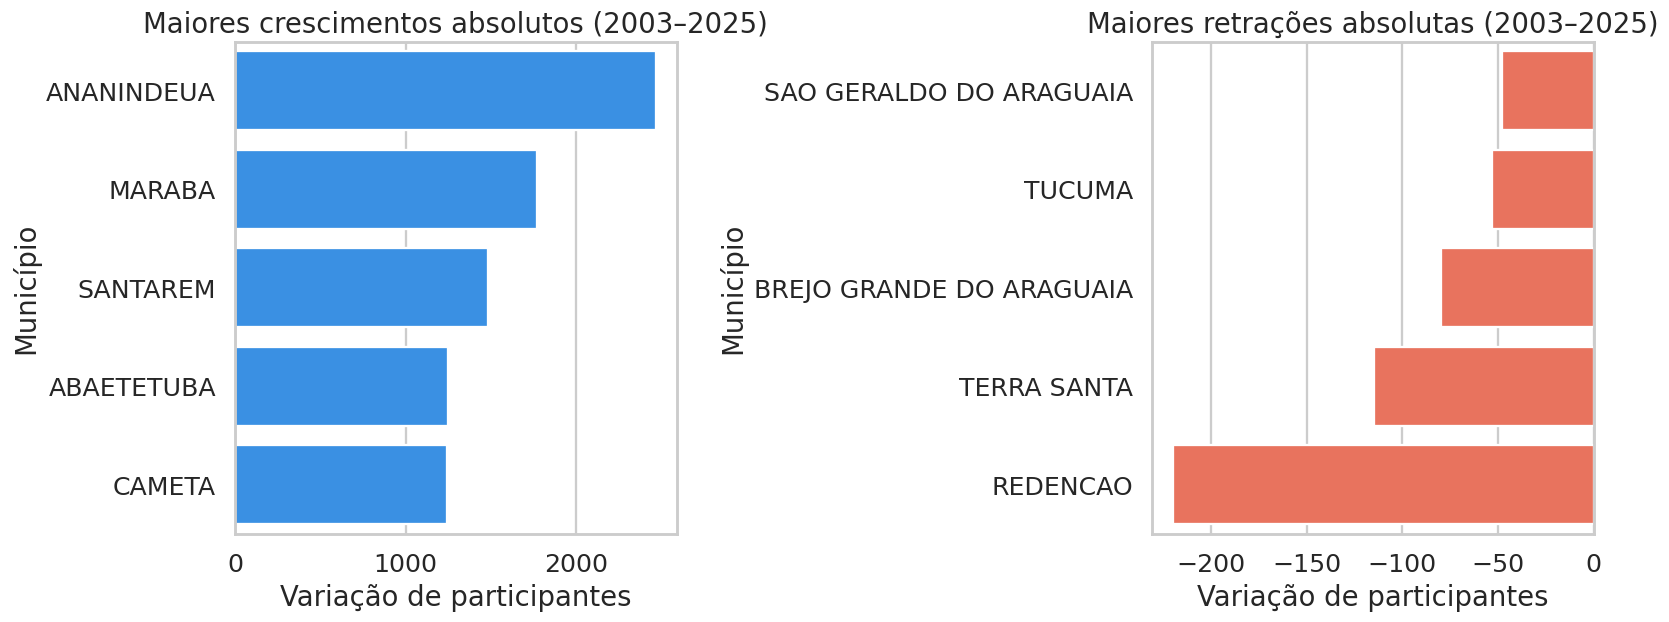

In [4]:
# Comparação municipal entre 2003 e 2025
crescimento_municipal = eda2.calcular_crescimento_municipal(painel_esc,ano_inicial=2003,ano_final=2025)

# Separar municípios comparáveis e não comparáveis
crescimento_comparavel = (crescimento_municipal.loc[crescimento_municipal["comparavel"]].copy())
crescimento_nao_comparavel = (crescimento_municipal.loc[~crescimento_municipal["comparavel"]].copy())


# Selecionar os cinco municípios com maiores crescimentos
maiores_crescimentos = (crescimento_comparavel.nlargest(5, "variacao_absoluta")
    .sort_values("variacao_absoluta", ascending=False))

# Selecionar os cinco municípios com maiores retrações
maiores_retracoes = (crescimento_comparavel.nsmallest(5, "variacao_absoluta")
    .sort_values("variacao_absoluta", ascending=False))

# Criar gráficos
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=maiores_crescimentos,
    x="variacao_absoluta",
    y="NO_MUNICIPIO_TERRITORIO",
    color='dodgerblue',
    ax=axes[0])
axes[0].set_title("Maiores crescimentos absolutos (2003–2025)")
axes[0].set_xlabel("Variação de participantes")
axes[0].set_ylabel("Município")

sns.barplot(
    data=maiores_retracoes,
    x="variacao_absoluta",
    y="NO_MUNICIPIO_TERRITORIO",
    color='tomato',
    ax=axes[1])
axes[1].set_title("Maiores retrações absolutas (2003–2025)")
axes[1].set_xlabel("Variação de participantes")
axes[1].set_ylabel("Município")

plt.tight_layout()
plt.show()


### Comentários

A comparação municipal foi realizada entre 2003 e 2025, considerando os municípios com registros nos dois anos. Foram identificados 140 municípios comparáveis. Nesse conjunto, 127 municípios apresentaram aumento no número de participantes e 13 apresentaram redução. Portanto, a expansão foi predominante, embora não tenha ocorrido de maneira uniforme no território.

#### Maiores aumentos absolutos

| Município  | Participantes em 2003 | Participantes em 2025 | Variação absoluta |
| ---------- | ---------------------:| ---------------------:| -----------------:|
| Ananindeua | 2.348                 | 4.813                 | +2.465            |
| Marabá     | 1.150                 | 2.922                 | +1.772            |
| Santarém   | 2.700                 | 4.185                 | +1.485            |
| Abaetetuba | 846                   | 2.094                 | +1.248            |
| Cametá     | 459                   | 1.700                 | +1.241            |

#### Maiores retrações absolutas

| Município                | Participantes em 2003 | Participantes em 2025 | Variação absoluta |
| ------------------------ | ---------------------:| ---------------------:| -----------------:|
| Redenção                 | 679                   | 459                   | -220              |
| Terra Santa              | 135                   | 20                    | -115              |
| Brejo Grande do Araguaia | 89                    | 9                     | -80               |
| Tucumã                   | 220                   | 167                   | -53               |
| São Geraldo do Araguaia  | 277                   | 229                   | -48               |

Alguns municípios de menor porte apresentaram variações percentuais muito elevadas, tanto positivas quanto negativas. Esses percentuais precisam ser interpretados considerando o tamanho da base inicial: uma diferença de poucas dezenas de participantes pode produzir uma variação relativa expressiva quando o valor de partida é pequeno.

A expansão da participação entre 2003 e 2025 alcançou a maior parte dos municípios comparáveis. Entretanto, o crescimento absoluto se concentrou especialmente em municípios com maior número de participantes, como Ananindeua, Marabá e Santarém. Ao mesmo tempo, alguns municípios registraram retrações, demonstrando que a expansão não foi homogênea.



## 3. Participação relativa dos municípios

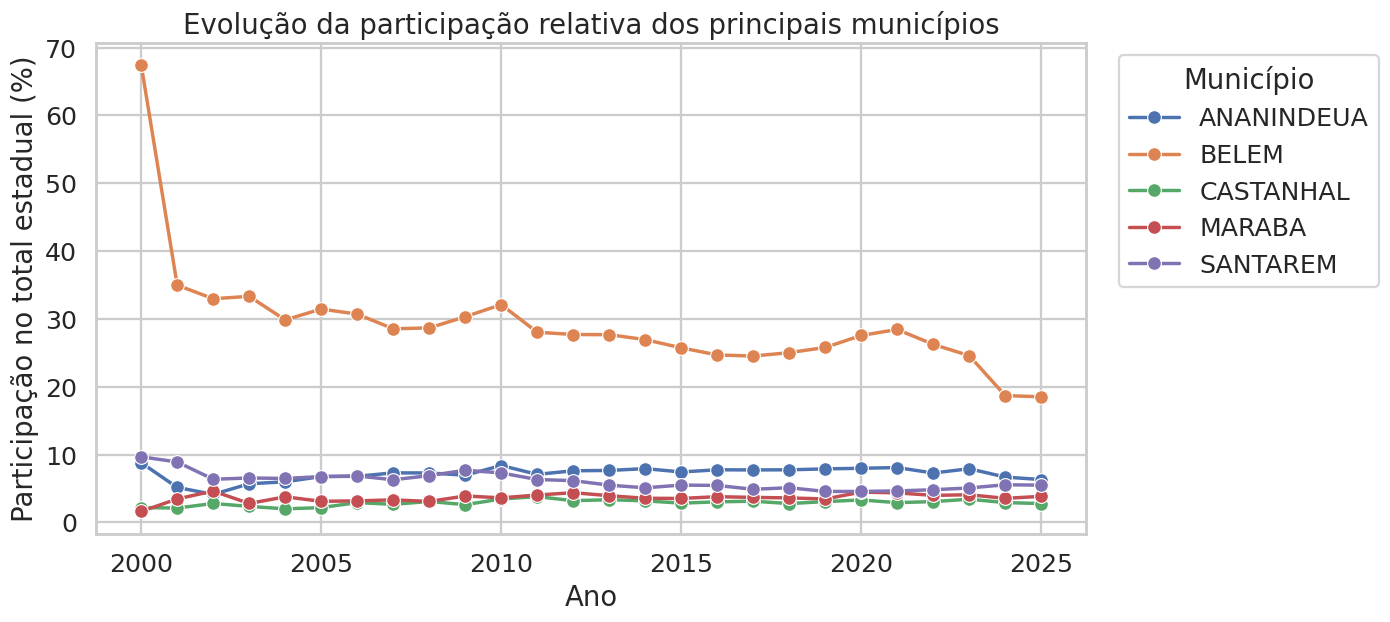

In [5]:
participacao_municipal = eda2.calcular_participacao_municipal(painel_esc)
ano_mais_recente = participacao_municipal["ano"].max()

top_municipios = (participacao_municipal.loc[participacao_municipal["ano"].eq(ano_mais_recente)]
    .nlargest(5, "participacao_pct")["CO_MUNICIPIO_TERRITORIO"])

serie_top = participacao_municipal.loc[participacao_municipal["CO_MUNICIPIO_TERRITORIO"].isin(top_municipios)].copy()


df_plot = serie_top[serie_top["ano"].between(2000, 2025)]
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=df_plot ,
    x="ano",
    y="participacao_pct",
    hue="NO_MUNICIPIO_TERRITORIO",
    marker="o")
plt.title("Evolução da participação relativa dos principais municípios")
plt.xlabel("Ano")
plt.ylabel("Participação no total estadual (%)")
plt.legend(title="Município", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



### Comentários

A distribuição territorial mostra concentração importante nos municípios mais populosos e nos principais centros urbanos do estado. Belém ocupa posição destacada em todo o recorte recente.

Em 2025, Belém registrou 14.121 participantes, correspondendo a 18,5% do total estadual. Ananindeua aparece em seguida, com 4.813 participantes (6,3%), seguida por Santarém, com 4.185 (5,5%), e Marabá, com 2.922 (3,8%).

| Município   | Participantes em 2025 | Participação estadual |
| ----------- | ---------------------:| ---------------------:|
| Belém       | 14.121                | 18,5%                 |
| Ananindeua  | 4.813                 | 6,3%                  |
| Santarém    | 4.185                 | 5,5%                  |
| Marabá      | 2.922                 | 3,8%                  |
| Castanhal   | 2.117                 | 2,8%                  |
| Abaetetuba  | 2.094                 | 2,7%                  |
| Parauapebas | 1.792                 | 2,3%                  |
| Cametá      | 1.700                 | 2,2%                  |
| Bragança    | 1.444                 | 1,9%                  |
| Barcarena   | 1.342                 | 1,8%                  |

A participação dos municípios foi calculada em relação ao total estadual de cada ano. A auditoria da planilha confirma que a soma dos percentuais municipais é igual a 100% em todos os anos de 1998 a 2025, considerando diferenças residuais de arredondamento numérico.

Belém concentra parcela expressiva dos participantes, mas a participação no ENEM está distribuída por um conjunto amplo de municípios. Os dez municípios com maior participação em 2025 representam aproximadamente 47,9% do total estadual. Isso evidencia a importância dos principais centros urbanos, sem eliminar a contribuição dos demais municípios.



## 4. Concentração territorial

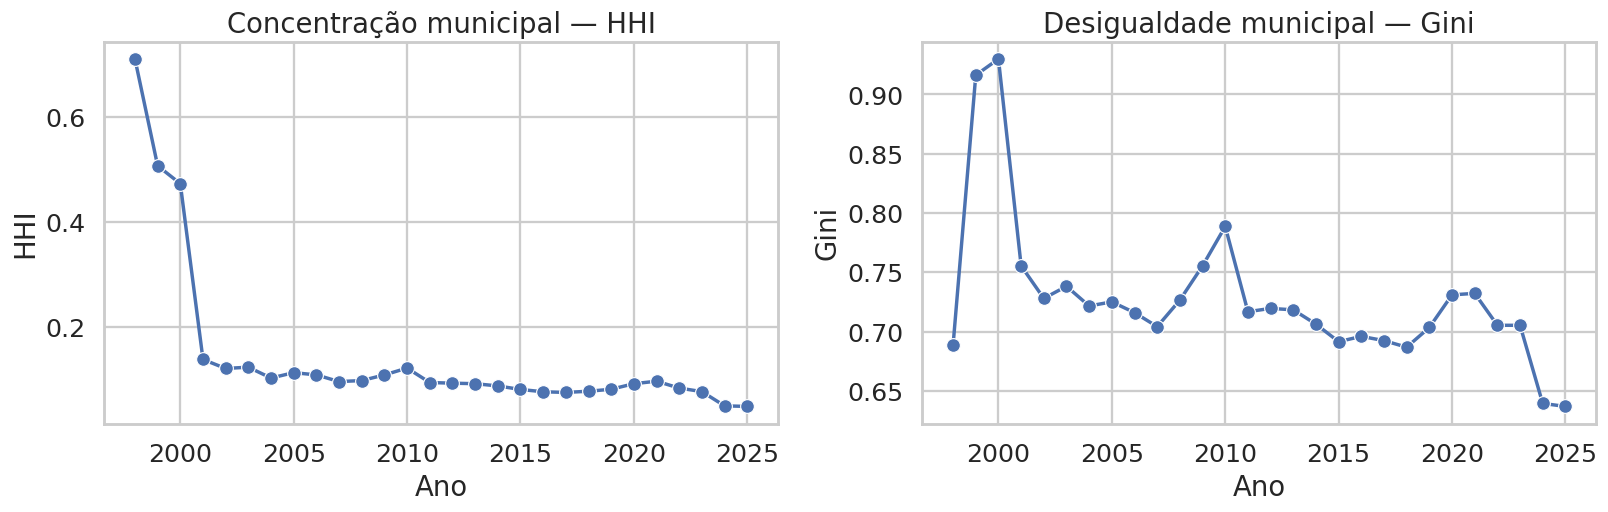

In [6]:
concentracao = eda2.calcular_concentracao_municipal(painel_esc)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=concentracao, x="ano", y="hhi", marker="o", ax=axes[0])
axes[0].set(title="Concentração municipal — HHI", xlabel="Ano", ylabel="HHI")

sns.lineplot(data=concentracao, x="ano", y="gini", marker="o", ax=axes[1])
axes[1].set(title="Desigualdade municipal — Gini", xlabel="Ano", ylabel="Gini")

plt.tight_layout()
plt.show()

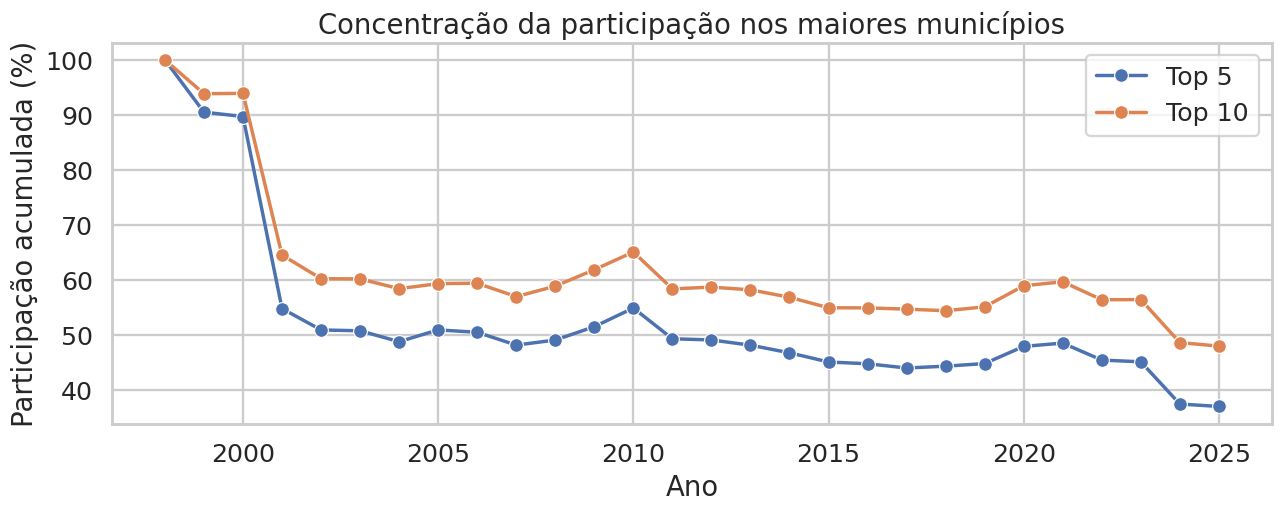

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=concentracao, x="ano", y="top5_pct", marker="o", label="Top 5")
sns.lineplot(data=concentracao, x="ano", y="top10_pct", marker="o", label="Top 10")
ax.set(
    title="Concentração da participação nos maiores municípios",
    xlabel="Ano",
    ylabel="Participação acumulada (%)",
)
plt.tight_layout()
plt.show()

### Comentários

Os indicadores de concentração mostram uma redução da concentração territorial ao longo da série, especialmente quando se compara o início da década de 2000 com os anos mais recentes.

O índice Herfindahl-Hirschman (HHI) caiu de 0,1389 em 2001 para 0,0495 em 2025. A participação conjunta dos cinco maiores municípios também diminuiu: passou de aproximadamente 54,7% em 2001 para 36,9% em 2025. Para os dez maiores municípios, a proporção caiu de 64,5% para 47,9%.

| Ano  | HHI    | Participação dos 5 maiores | Participação dos 10 maiores |
| ---- | ------:| --------------------------:| ---------------------------:|
| 2001 | 0,1389 | 54,7%                      | 64,5%                       |
| 2005 | 0,1137 | 50,9%                      | 59,3%                       |
| 2010 | 0,1224 | 54,8%                      | 65,0%                       |
| 2015 | 0,0817 | 45,0%                      | 54,9%                       |
| 2020 | 0,0927 | 47,9%                      | 58,9%                       |
| 2021 | 0,0975 | 48,5%                      | 59,6%                       |
| 2023 | 0,0777 | 45,1%                      | 56,4%                       |
| 2024 | 0,0506 | 37,4%                      | 48,6%                       |
| 2025 | 0,0495 | 36,9%                      | 47,9%                       |

O índice de Gini municipal também recuou, passando de aproximadamente 0,755 em 2001 para 0,637 em 2025. Em conjunto, os indicadores apontam para uma distribuição menos concentrada da participação entre os municípios.

A participação no ENEM tornou-se territorialmente mais distribuída no Pará. Belém continua sendo o principal polo, mas sua participação relativa e a concentração nos maiores municípios diminuíram ao longo do período. A redução mais acentuada dos indicadores em 2024 e 2025 acompanha a elevação do número de participantes e a presença de registros nos 144 municípios.

Observação: Os indicadores de 1998 a 2000 são especialmente sensíveis à cobertura municipal incompleta. A comparação mais consistente da concentração começa em 2001, quando a cobertura já é maior, e deve considerar também a expansão do número de municípios com registros. além disso, HHI, Gini e participação dos maiores municípios descrevem a distribuição dos registros entre municípios. Eles não medem, isoladamente, acesso, qualidade ou desigualdade educacional.



## 5. Períodos de mudança

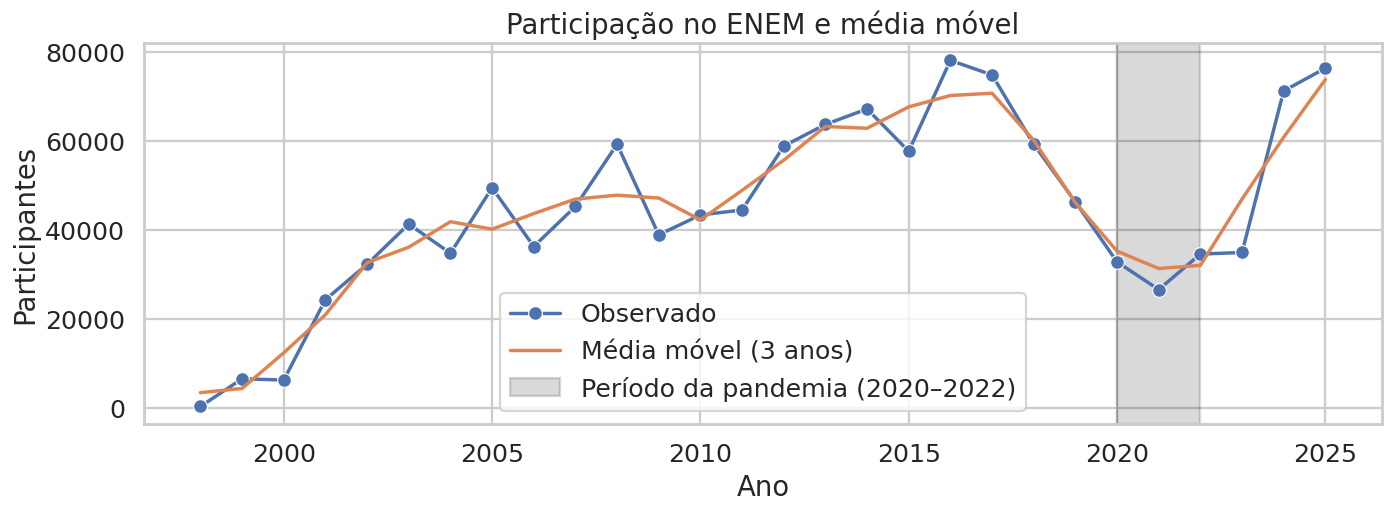

In [8]:
indicadores_temporais = eda2.calcular_indicadores_temporais(
    participacao_anual,
    coluna_valor="participantes",
    janela=3)

fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=indicadores_temporais, x="ano", y="participantes", label="Observado", marker="o", ax=ax)
sns.lineplot(data=indicadores_temporais, x="ano", y="media_movel", label="Média móvel (3 anos)", ax=ax)
ax.set(
    title="Participação no ENEM e média móvel",
    xlabel="Ano",
    ylabel="Participantes",
)
# Destaque do período da pandemia
ax.axvspan(
    2020, 2022,
    color="black",
    alpha=0.15,
    label="Período da pandemia (2020–2022)"
)
ax.legend()
plt.tight_layout()
plt.show()

### Comentários

A série anual revela diferentes fases. Entre 2001 e 2008, houve expansão geral, embora com retrações pontuais em 2004 e 2006. Em 2009, ocorreu uma redução expressiva de 34,4%, seguida por recuperação gradual e novo crescimento entre 2012 e 2016.
**Periodização identificada**

* **2001–2008** : Expansão geral, com oscilações
* **2009**      : Mudança do enem e da base de dados
* **2010–2016** : Recuperação e expansão
* **2017–2021** : Retração continuada + pandemia
* **2022–2023** : Recuperação 
* **2024–2025** : recuperação e estabilidade

A partir de 2017, iniciou-se uma fase de retração, que se estendeu até 2021. O menor total da série desde 2001 ocorreu em 2021, com 26.554 participantes. A recuperação começou em 2022, mas o salto de 2024 se destaca em relação às variações anuais anteriores. Em 2024, o total aumentou 36.295 participantes em relação a 2023. Em 2025, o acréscimo foi de 5.089 participantes.

A participação apresenta ciclos bem definidos de expansão e retração. A queda entre 2017 e 2021 foi seguida por recuperação, com uma mudança de patamar em 2024. A magnitude dessa mudança recomenda que o resultado seja tratado como um ponto de atenção para a interpretação da série, e não apenas como continuidade da tendência anterior.

A taxa de crescimento anual composta (CAGR) de 22,95% entre 1998 e 2025 é matematicamente calculada a partir dos totais extremos, mas é fortemente afetada pela pequena cobertura de 1998. Assim, não representa adequadamente o ritmo de crescimento ao longo de todo o período.


## 6. Presença e ausência

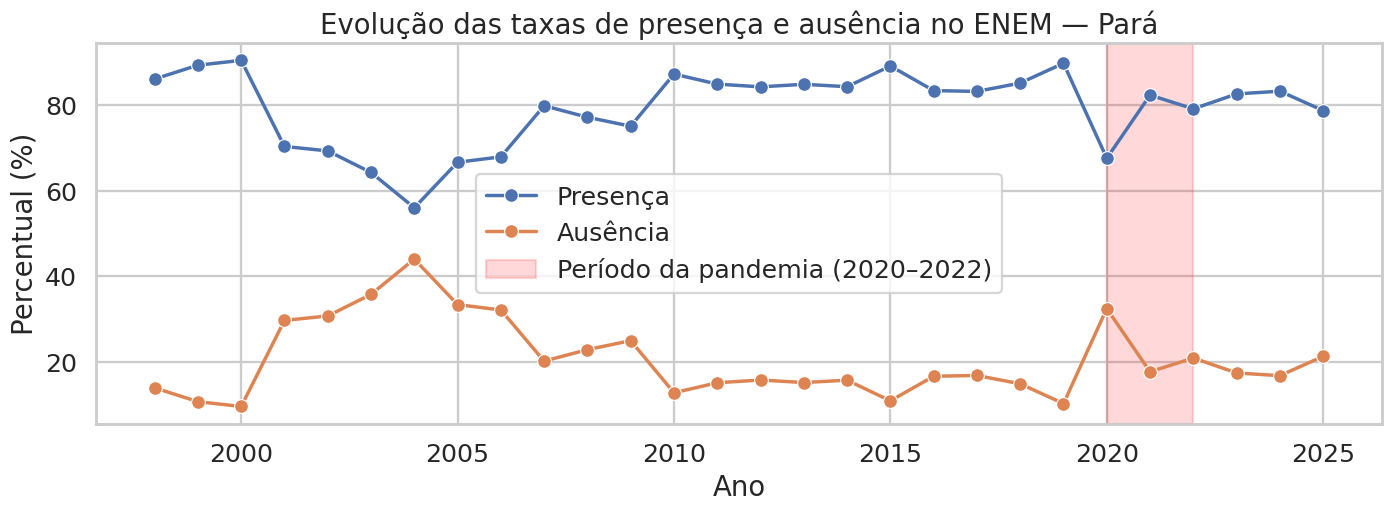

In [9]:
painel_presenca = eda2.padronizar_presenca_ausencia(painel_esc)

presenca_anual = (painel_presenca.groupby("ano", as_index=False)
    .agg(participantes=("n_participantes", "sum"),
         presentes=("n_presentes", "sum"),
         ausentes=("n_ausentes", "sum"),
         informados=("n_presenca_informada", "sum")))

presenca_anual["pct_presenca"] = (presenca_anual["presentes"]/ presenca_anual["informados"] * 100)
presenca_anual["pct_ausencia"] = (presenca_anual["ausentes"]/ presenca_anual["informados"] * 100)


fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=presenca_anual,x="ano",y="pct_presenca",marker="o",
             label="Presença",ax=ax)

sns.lineplot(data=presenca_anual,x="ano",y="pct_ausencia",marker="o",
             label="Ausência",ax=ax)

# Destaque do período da pandemia
ax.axvspan(2020, 2022,color="red",alpha=0.15,label="Período da pandemia (2020–2022)")

ax.set(title="Evolução das taxas de presença e ausência no ENEM — Pará",
       xlabel="Ano",
       ylabel="Percentual (%)")

ax.legend()
plt.tight_layout()
plt.show()

### Comentários

A proporção de presença variou consideravelmente ao longo da série. Entre 1999 e 2008, os percentuais oscilaram, em geral, entre aproximadamente 56% e 90%. Em 2004, foi registrado o menor percentual de presença desse intervalo, com 56,0%.

Entre 2010 e 2019, a presença ficou predominantemente acima de 80%, alcançando 89,8% em 2019. Em 2020, ocorreu uma redução expressiva para 67,6%, seguida de recuperação em 2021 e 2022.

Em 2025, foram registrados 60.045 presentes e 16.219 ausentes, correspondendo a 78,7% de presença e 21,3% de ausência.

| Ano  | Participantes | Presentes | Ausentes | Presença |
| ---- | -------------:| ---------:| --------:| --------:|
| 2001 | 24.295        | 17.089    | 7.206    | 70,3%    |
| 2004 | 34.715        | 19.442    | 15.273   | 56,0%    |
| 2008 | 59.189        | 45.675    | 13.514   | 77,2%    |
| 2010 | 43.307        | 37.791    | 5.516    | 87,3%    |
| 2015 | 57.607        | 51.355    | 6.252    | 89,1%    |
| 2019 | 46.241        | 41.520    | 4.721    | 89,8%    |
| 2020 | 32.759        | 22.137    | 10.622   | 67,6%    |
| 2021 | 26.554        | 21.867    | 4.687    | 82,3%    |
| 2022 | 34.524        | 27.317    | 7.207    | 79,1%    |
| 2023 | 34.880        | 28.819    | 6.061    | 82,6%    |
| 2024 | 71.175        | 59.260    | 11.915   | 83,3%    |
| 2025 | 76.264        | 60.045    | 16.219   | 78,7%    |

A presença dos inscritos não é constante e apresenta oscilações importantes. O ano de 2020 se destaca pela queda acentuada, enquanto 2025 apresenta percentual de presença inferior ao observado em 2024. Portanto, o aumento do número de inscritos não significa necessariamente aumento proporcional do número de participantes presentes.

A distinção entre inscritos e presentes é essencial: o total de participantes utilizado nas análises de participação representa a inscrição registrada, enquanto a presença corresponde ao comparecimento informado na base.


## 7. Síntese dos resultados

Os resultados mostram que a participação registrada no ENEM no Pará cresceu expressivamente entre 1998 e 2025. Entretanto, essa expansão não ocorreu de forma contínua e precisa ser interpretada considerando as limitações de cobertura dos primeiros anos da série.

**Expansão da participação**

O número de registros passou de 288, em 1998, para 76.264, em 2025. Apesar do crescimento expressivo, a cobertura municipal muito limitada nos primeiros anos impede uma comparação direta de toda a série sem ressalvas.

**Expansão nos municípios**

A comparação entre 2003 e 2025 permite uma análise territorial mais consistente. Dos 140 municípios comparáveis, 127 apresentaram aumento no número de participantes. Portanto, a expansão alcançou a maioria dos municípios paraenses, embora alguns tenham registrado retração.Os maiores aumentos absolutos ocorreram em Ananindeua, Marabá, Santarém, Abaetetuba e Cametá.

**Distribuição territorial da participação**

Belém permanece como principal polo de participação, mas sua concentração relativa diminuiu. Em 2025, o município reuniu 18,5% dos participantes do estado, enquanto os dez municípios com maior participação concentraram aproximadamente 47,9% do total.A redução dos indicadores HHI e Gini, assim como da participação conjunta dos maiores municípios, reforça a tendência de menor concentração territorial ao longo do período.

**Oscilações ao longo da série histórica**

A evolução da participação apresentou diferentes fases: expansão até 2008, retração em 2009, recuperação até 2016, nova queda entre 2017 e 2021 e retomada a partir de 2022.Destaca-se o crescimento de 104,1% em 2024, uma variação particularmente acentuada em relação ao ano anterior e que merece atenção na interpretação da série.

**Inscrição e comparecimento**

O número de inscritos não corresponde ao número de participantes que efetivamente compareceram ao exame. Em 2025, aproximadamente 78,7% dos inscritos foram registrados como presentes.Essa diferença mostra a importância de analisar separadamente as inscrições e o comparecimento, evitando tratar essas duas medidas como equivalentes.

<div style="background-color: #E2E8F0; padding: 12px; border-radius: 6px;">
    
**Síntese Final**  
A participação no ENEM no Pará cresceu e alcançou a maioria dos municípios do estado. Embora Belém continue concentrando a maior parcela dos participantes, os indicadores apontam para uma distribuição territorial menos concentrada. Essa expansão, contudo, ocorreu com oscilações importantes, incluindo períodos de retração e um crescimento excepcional em 2024. A interpretação da trajetória histórica também exige considerar a cobertura municipal limitada nos primeiros anos e distinguir o número de inscritos do número de presentes
</div>